#INFORMAÇÕES
###Dupla
um colega e Pedro Vieira

#APRESENTAÇÃO DO PROBLEMA
O problema escolhido para ser resolvido no kaggle foi o ["Store Sales - Time Series Forecasting"](https://www.kaggle.com/competitions/store-sales-time-series-forecasting/data), no qual é necessário predizer as vendas que serão realizadas para famílias nas lojas Favorita, do Equador.

#DADOS DO PROBLEMA
 - 5 tabelas

**train.csv** - Dados de treinamento com séries temporais das características das lojas, famílias, em promoção e vendas alvo

**test.csv** - Dados de teste

**stores.csv** - Armazenar metadados de cidade, estado, tipo e cluster

**oil.csv** - Preço diário do petróleo

**holidays_events.csv** - Feriados e eventos com metadados

# TRANSFORMAÇÃO BASE DOS DADOS
Join entre todas as tabelas para mesclar os dados em apenas uma

#ANÁLISE DOS DADOS
A tabela de treino é composta pelas seguintes colunas:

**ID** - ID da venda

**DATE** - Armazena a data de compra

**STORE_NBR** - Identifica a loja onde os produtos foram vendidos

**SALES** - Identifica a quantidade de vendas na loja

**ONPROMOTION** - Indica o número total de itens de uma fam~ilia de produtos que estavam em promoção em uma determinada loja

**CITY** - Armazena a cidade

**STATE** - Armazena o estado da cidade

**STORE_TYPE** - Identifica o tipo de loja

**CLUSTER** - Identifica o cluster da loja

**OIL_PRICE** - Identifica o vaolr do petróleo

**TRANSACTIONS** - Número de transações

**HOLIDAY_NAME** - Identifica o nome do feriado

**HOLIDAY_TYPE** - Identifica o tipo do feriado


#NOTAS ADICIONAIS
Os salários no setor público são pagos quinzenalmente, nos dias 15 e 30 do mês. As vendas nos supermercados podem ser afetadas por isso.

Um terremoto de magnitude 7,8 atingiu o Equador em 16 de abril de 2016. A população se mobilizou em esforços de ajuda humanitária, doando água e outros produtos de primeira necessidade, o que afetou significativamente as vendas em supermercados durante várias semanas após o terremoto.





In [ ]:
# from google.colab import drive
# drive.mount('/gdrive')
# %cd <pasta com os dados no seu Drive>

Drive already mounted at /gdrive; to attempt to forcibly remount, call drive.mount("/gdrive", force_remount=True).
/gdrive/MyDrive/faculdade/8 semestre/INTELIGÊNCIA COMPUTACIONAL/TRABALHOS/TP1


#IMPORTS

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.metrics import mean_absolute_error, root_mean_squared_log_error
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.dummy import DummyRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import StackingRegressor
from sklearn.linear_model import Ridge

#PREPARAÇÃO DOS DADOS

In [ ]:
df = pd.read_csv("train_consolidated.csv", parse_dates=["date"])

df.head()

,id,date,store_nbr,family,sales,onpromotion,city,state,store_type,cluster,oil_price,transactions,holiday_name,holiday_type
0,3,2013-01-01,1,BEVERAGES,0.000,0,Quito,Pichincha,D,13,NaN,NaN,Primer dia del ano,Holiday
1,138326,2013-03-19,4,MAGAZINES,0.000,0,Quito,Pichincha,D,9,92.44,1331.0,NaN,NaN
2,138327,2013-03-19,4,MEATS,253.461,0,Quito,Pichincha,D,9,92.44,1331.0,NaN,NaN
3,138328,2013-03-19,4,PERSONAL CARE,103.000,0,Quito,Pichincha,D,9,92.44,1331.0,NaN,NaN
4,138329,2013-03-19,4,PET SUPPLIES,0.000,0,Quito,Pichincha,D,9,92.44,1331.0,NaN,NaN


#CORREÇÕES ESTRUTURAIS NO DATABASE

In [ ]:
# 1) ORDENAÇÃO TEMPORAL - Obrigatório para qualquer série temporal
df = df.sort_values(["store_nbr", "family", "date"]).reset_index(drop=True)

# 2) TIPOS
cat_cols = ["store_nbr", "family", "city", "state", "store_type", "cluster", "holiday_name", "holiday_type"]

for col in cat_cols:
    df[col] = df[col].astype("category")


# 3) NORMALIZAÇÃO NUMÉRICA
def clean_numeric(col):
    return (
        col.astype(str)
        .str.strip()
        .str.replace(" ", "")
        .str.replace(".", "", regex=False)   # remove milhar
        .str.replace(",", ".", regex=False)  # decimal
    )

df["oil_price"] = pd.to_numeric(clean_numeric(df["oil_price"]), errors="coerce")
df["transactions"] = pd.to_numeric(clean_numeric(df["transactions"]), errors="coerce")

num_cols = ["sales", "onpromotion", "oil_price", "transactions"]
df[num_cols] = df[num_cols].apply(pd.to_numeric, errors="coerce")


# 4) TRATAMENTO CORRETO DOS NaN (31% dos oil_price eram Nan e 8% das transactions eram NaN)

# ---- OIL PRICE ----
# Série temporal global → usa forward fill
# Justificativa:
# - preço do petróleo é contínuo no tempo
# - não depende da loja
# - usar média distorce tendência temporal

# oil_price
df["oil_price"] = df["oil_price"].ffill()

# ---- TRANSACTIONS ----
# Dependente de loja → precisa respeitar agrupamento
# Justificativa:
# - cada loja tem comportamento próprio
# - preencher globalmente gera ruído

df["transactions"] = df.groupby("store_nbr", observed=True)["transactions"].ffill()

# fallback para casos iniciais ainda NaN
df["transactions"] = df["transactions"].fillna(0)


# 5) VALIDAÇÃO FINAL
print("oil_price NaN:", df["oil_price"].isna().sum())
print("transactions NaN:", df["transactions"].isna().sum())

oil_price NaN: 1
transactions NaN: 0


#REDUÇÃO DO DATASET UTILIZADO
Apenas para entrega parcial

In [ ]:
# opção: recorte temporal + subset de lojas

df = df[df["date"] >= "2016-01-01"]

stores_sample = df["store_nbr"].cat.categories[:10]
df = df[df["store_nbr"].isin(stores_sample)]

df = df.sort_values(["store_nbr", "family", "date"]).reset_index(drop=True)

print("Novo tamanho:", len(df))

Novo tamanho: 21153


#FEATURE ENGINEERING

In [ ]:
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["day"] = df["date"].dt.day
df["dayofweek"] = df["date"].dt.dayofweek
df["weekofyear"] = df["date"].dt.isocalendar().week.astype(int)

# payday
df["is_payday"] = df["day"].isin([15, 30]).astype(int)

# terremoto
df["post_earthquake"] = (df["date"] >= "2016-04-16").astype(int)

#LAGS
###Ganho de performance

Serve para fazer o modelo usar comportamento do passado na previsão. Exemplo: Dia 10 a venda foi 100. Dia 11 a venda foi 120, mas utilizará o 100. Permite ao modelo aprender padrão temporal

In [ ]:
# utilizar quando for dataset completo
# # garantir ordenação correta
# df = df.sort_values(["store_nbr", "family", "date"])

# for lag in [1, 7, 14]:
#     df[f"lag_{lag}"] = df.groupby(
#         ["store_nbr", "family"], observed=True
#     )["sales"].shift(lag)

# # remover NaNs gerados pelos lags
# df = df.dropna()

# garantir ordenação correta
df = df.sort_values(["store_nbr", "family", "date"])

for lag in [1, 7, 14]:
    df[f"lag_{lag}"] = df.groupby(
        ["store_nbr", "family"], observed=True
    )["sales"].shift(lag)

# remover NaNs gerados pelos lags
df = df.dropna()

#SEPARAÇÃO DE DADOS

In [ ]:
target = "sales"

drop_cols = ["id", "date", "sales"]

X = df.drop(columns=drop_cols)
y = df[target]

#PIPELINE

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

cat_cols = X.select_dtypes(include=["category", "object"]).columns
num_cols = X.select_dtypes(include=["int64", "float64"]).columns

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ohe", OneHotEncoder(handle_unknown="ignore"))
])

preprocess = ColumnTransformer([
    ("num", numeric_pipe, num_cols),
    ("cat", categorical_pipe, cat_cols)
])

#MÉTRICA
RMSLE + MAE

In [ ]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, root_mean_squared_log_error
import numpy as np

def eval_model(model, X, y):
    tscv = TimeSeriesSplit(n_splits=5)

    rmsle_list = []
    mae_list = []

    for train_idx, val_idx in tscv.split(X):
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

        model.fit(X_train, np.log1p(y_train))

        pred = np.expm1(model.predict(X_val))
        pred = np.clip(pred, 0, None)

        rmsle_list.append(root_mean_squared_log_error(y_val, pred))
        mae_list.append(mean_absolute_error(y_val, pred))

    return np.mean(rmsle_list), np.mean(mae_list)

#MODELOS SIMPLES

In [ ]:
from sklearn.dummy import DummyRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor

models = {
    "baseline": Pipeline([
        ("prep", preprocess),
        ("model", DummyRegressor(strategy="mean"))
    ]),

    "tree": Pipeline([
        ("prep", preprocess),
        ("model", DecisionTreeRegressor(max_depth=10))
    ]),

    "knn": Pipeline([
        ("prep", preprocess),
        ("model", KNeighborsRegressor(n_neighbors=5))
    ])
}

for name, model in models.items():
    rmsle, mae = eval_model(model, X, y)
    print(name, "RMSLE:", rmsle, "MAE:", mae)

baseline RMSLE: 2.5582719523671753 MAE: 594.9706308879058
tree RMSLE: 0.6540485603851567 MAE: 237.9971264687768
knn RMSLE: 0.973619154103137 MAE: 234.94205382669742


#META-LEARNING

In [ ]:
from sklearn.ensemble import StackingRegressor
from sklearn.linear_model import Ridge

stack_model = Pipeline([
    ("prep", preprocess),
    ("model", StackingRegressor(
        estimators=[
            ("tree", DecisionTreeRegressor(max_depth=10)),
            ("knn", KNeighborsRegressor(n_neighbors=5))
        ],
        final_estimator=Ridge()
    ))
])

rmsle, mae = eval_model(stack_model, X, y)
print("stack RMSLE:", rmsle, "MAE:", mae)

stack RMSLE: 0.6029485960299452 MAE: 210.4350827398999


#ENVIAR PARA O KAGGLE

In [ ]:
# 1) LEITURA E ORDENAÇÃO DO TEST

test = pd.read_csv("test.csv", parse_dates=["date"])
test = test.sort_values(["store_nbr", "family", "date"]).reset_index(drop=True)


# 2) CRIAR HISTÓRICO DE LAGS (A PARTIR DO TREINO)
# pegar últimos 14 dias de cada grupo

last_values = df.sort_values("date").groupby(
    ["store_nbr", "family"], observed=True
).tail(14)

# montar dicionário de histórico
lag_dict = {}

for (store, family), group in last_values.groupby(["store_nbr", "family"]):
    group = group.sort_values("date")
    lag_dict[(store, family)] = group["sales"].values


# 3) FUNÇÃO PARA BUSCAR LAG
def get_lag(row, lag):
    key = (row["store_nbr"], row["family"])
    values = lag_dict.get(key, None)

    if values is None or len(values) < lag:
        return 0

    return values[-lag]


# 4) CRIAR LAGS NO TEST
for lag in [1, 7, 14]:
    test[f"lag_{lag}"] = test.apply(lambda row: get_lag(row, lag), axis=1)


# 5) FEATURE ENGINEERING (MESMO DO TREINO)
test["year"] = test["date"].dt.year
test["month"] = test["date"].dt.month
test["day"] = test["date"].dt.day
test["dayofweek"] = test["date"].dt.dayofweek
test["weekofyear"] = test["date"].dt.isocalendar().week.astype(int)

test["is_payday"] = test["day"].isin([15, 30]).astype(int)
test["post_earthquake"] = (test["date"] >= "2016-04-16").astype(int)

# 6) SALVAR ID ANTES DE FILTRAR
test_ids = test["id"].copy()

# garantir mesmas colunas
for col in X.columns:
    if col not in test.columns:
        test[col] = 0

test = test[X.columns]


# 7) TREINO + PREDIÇÃO
model = stack_model

model.fit(X, np.log1p(y))

pred = np.expm1(model.predict(test))
pred = np.clip(pred, 0, None)


# 8) GERAR CSV
submission = pd.DataFrame({
    "id": test_ids,
    "sales": pred
})

submission.to_csv("submission.csv", index=False)


# 9) CHECK FINAL

print("Shape:", submission.shape)
print("NaNs:", submission.isna().sum().sum())

/tmp/ipykernel_22882/246846295.py:17: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for (store, family), group in last_values.groupby(["store_nbr", "family"]):


Shape: (28512, 2)
NaNs: 0


In [ ]:
from google.colab import files
files.download("submission.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

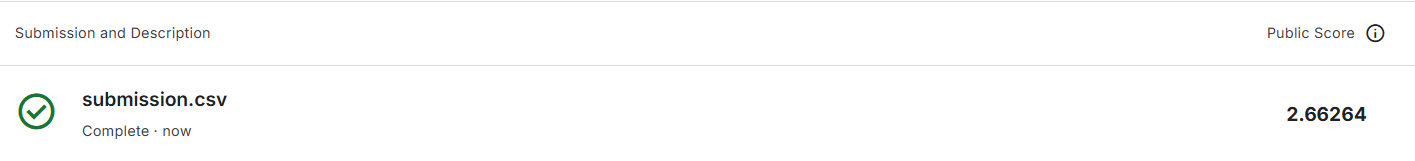